# Uncertainty and Reliability

Scope: Uncertainty and reliability in the WESAD protocol.

Input: Features; distinct internal calibration subjects.

Output and saved artifacts: `results/uncertainty_predictions.csv`, `uncertainty_splits.json`, `reliability.csv`, `risk_acceptance.csv`; reliability figure (under the configured output root; real `.parquet`, synthetic `.csv`).

Dependencies: Environment from `requirements.txt`, `src/` modules; setup dependencies only in notebook 00.

Full exploratory conformal prediction is executed in notebook 05 under `exploratory/conformal/`. This notebook keeps the secondary reliability pipeline separate.


In [1]:
from pathlib import Path
import os, sys
HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents) if (p / 'configs/config.yaml').is_file() and (p / 'src').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Start Jupyter inside the project folder; no machine-specific path is required')
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.config import load, setup, smoke_config
from src import workflow as w
SYNTHETIC = os.environ.get('WESAD_SYNTHETIC', '0') == '1'
c = load()
if SYNTHETIC: c = smoke_config(c)

# Reuse saved protocol instead of silently resetting extraction settings.
if not SYNTHETIC:
    import copy, json
    from src.config import fingerprint
    protocol_file = w.root(c) / 'protocol_lock.json'
    if protocol_file.is_file():
        from src.provenance import verify_lock
        saved_protocol = verify_lock(protocol_file)
        frozen = saved_protocol['config']
        if fingerprint(frozen) != saved_protocol['config_sha256']:
            raise ValueError('Saved protocol hash mismatch')
        c = copy.deepcopy(frozen)

setup(c)
print('Data mode:', 'SYNTHETIC EXECUTION ONLY' if SYNTHETIC else 'REAL WESAD')


Data mode: REAL WESAD


In [2]:
feature_file = w.root(c) / 'features' / ('chest_features.' + c['output']['feature_format'])
if not feature_file.exists():
    print('NOT EXECUTABLE: synchronized feature tables absent. See real_raw_audit report.')
else:
    tables = w.load_tables(c)
    predictions = w.uncertainty_stage(tables, c)
    print(predictions.groupby('subject_id').accepted.mean())
    print('Calibration is empirical. No guaranteed coverage on new individuals.')
    print('Conformal set size/coverage absent unless exploratory conformal is explicitly enabled.')


subject_id
2     1.000000
3     1.000000
4     0.985294
5     0.338710
6     1.000000
7     0.956522
8     0.782609
9     0.956522
10    0.957746
11    0.227273
13    0.528571
14    0.900000
15    0.600000
16    1.000000
17    0.029412
Name: accepted, dtype: float64
Calibration is empirical. No guaranteed coverage on new individuals.
Conformal set size/coverage absent unless exploratory conformal is explicitly enabled.


La quota di predizioni accettate varia sensibilmente tra soggetti, dal 2,94% al 100%. Il meccanismo di astensione mostra quindi una disponibilità di risposta non uniforme su individui nuovi. L’accettazione non implica correttezza: il suo beneficio deve essere verificato confrontando prestazioni e numerosità prima e dopo il rifiuto, anche separatamente per classe. In particolare, la bassissima accettazione di S17 limita l’utilità pratica del sistema per quel soggetto.

## Valutazione del rifiuto
Metriche prima/dopo, soglie per fold e disponibilità per classe.


### Rifiuto: risultati per soggetto

subject_id,threshold,n_total,n_accepted,n_rejected,acceptance,accuracy_before,accuracy_after,delta_accuracy,BA_before,BA_after,delta_BA,missing_classes_after
2,0.341,65,65,0,100.0%,70.8%,70.8%,0.0%,51.0%,51.0%,0.0%,0
3,0.353,66,66,0,100.0%,84.8%,84.8%,0.0%,71.8%,71.8%,0.0%,0
4,0.360,68,67,1,98.5%,75.0%,76.1%,1.1%,58.0%,59.2%,1.1%,0
5,0.644,62,21,41,33.9%,82.3%,100.0%,17.7%,74.8%,N/D,N/D,1
6,0.339,66,66,0,100.0%,80.3%,80.3%,0.0%,61.1%,61.1%,0.0%,0
7,0.378,69,66,3,95.7%,85.5%,87.9%,2.4%,82.6%,85.4%,2.8%,0
8,0.670,69,54,15,78.3%,81.2%,87.0%,5.9%,63.5%,66.7%,3.2%,0
9,0.425,69,66,3,95.7%,72.5%,75.8%,3.3%,53.3%,55.6%,2.2%,0
10,0.374,71,68,3,95.8%,57.7%,57.4%,-0.4%,49.5%,49.0%,-0.5%,0
11,0.750,66,15,51,22.7%,86.4%,100.0%,13.6%,77.0%,N/D,N/D,2


### Accettazione e recall per soggetto e classe

subject_id,class,n_total,n_accepted,acceptance,recall_before,recall_after
2,Baseline,37,37,100.0%,100.0%,100.0%
2,Stress,17,17,100.0%,52.9%,52.9%
2,Amusement,11,11,100.0%,0.0%,0.0%
3,Baseline,37,37,100.0%,97.3%,97.3%
3,Stress,18,18,100.0%,100.0%,100.0%
3,Amusement,11,11,100.0%,18.2%,18.2%
4,Baseline,37,37,100.0%,100.0%,100.0%
4,Stress,20,19,95.0%,65.0%,68.4%
4,Amusement,11,11,100.0%,9.1%,9.1%
5,Baseline,32,6,18.8%,84.4%,100.0%


### Disponibilità di risposta per classe

,n_total,n_accepted,acceptance
class,,,
Amusement,160,107,66.9%
Baseline,550,408,74.2%
Stress,295,243,82.4%


### Confronto medio sugli stessi soggetti
Include soltanto soggetti con tutte le classi presenti dopo il rifiuto. Controllare quanti soggetti restano: questo riepilogo può essere selettivo.

metric,mean_before,mean_after,n_subjects
Accuracy,74.8%,78.2%,12
Balanced accuracy,63.2%,64.7%,12


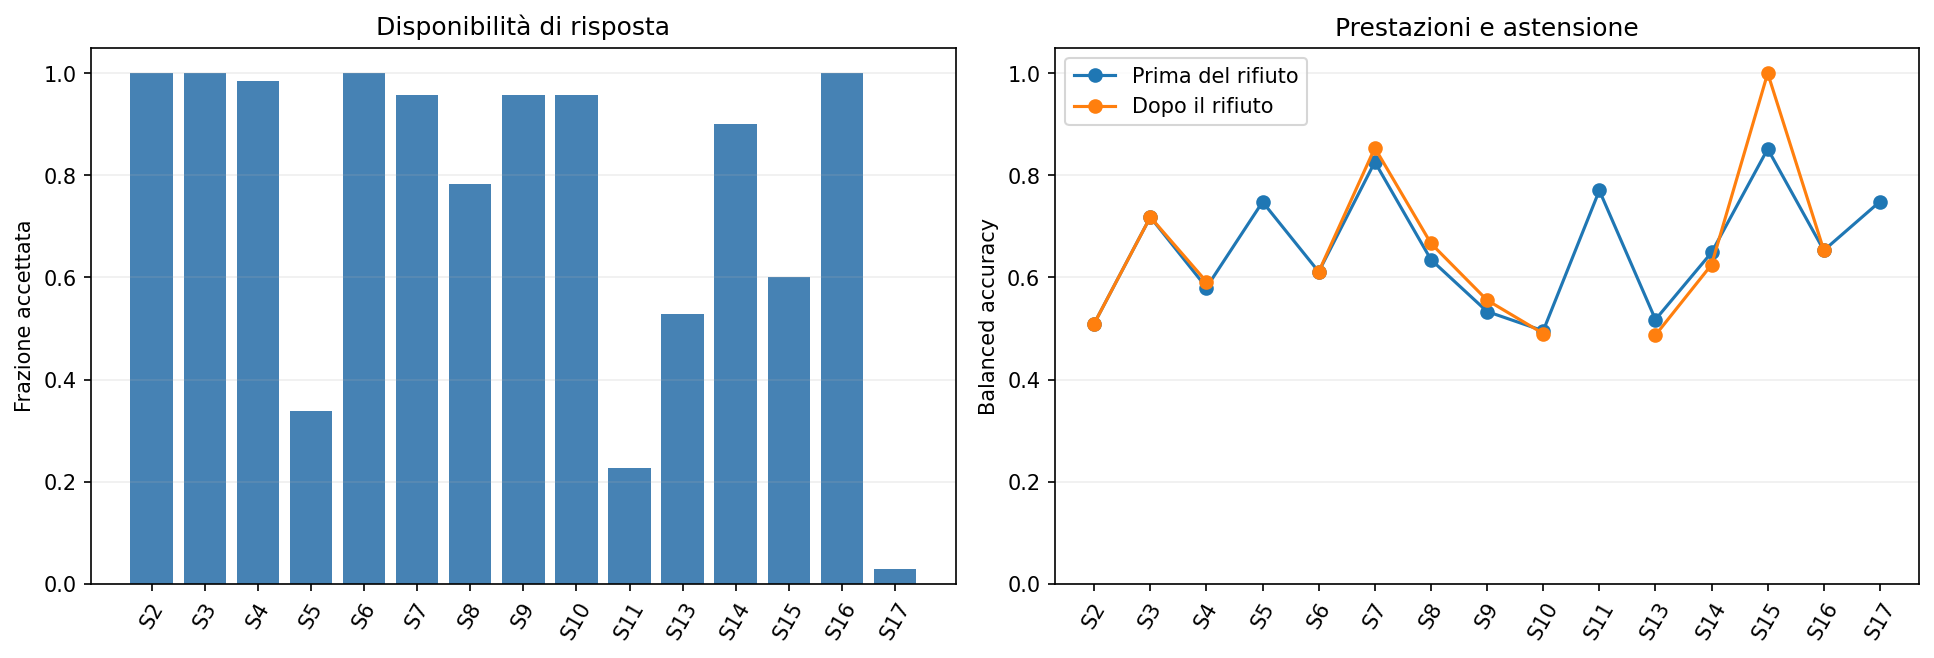

Il confronto usa label e prediction_raw della stessa procedura. Le prestazioni dopo il rifiuto riguardano un sottoinsieme selezionato e vanno lette insieme alla quota di finestre accettate.


In [3]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from io import BytesIO
from IPython.display import display, Image, Markdown
from sklearn.metrics import accuracy_score, recall_score

results_dir = w.root(c) / "results"

pred = pd.read_csv(results_dir / "uncertainty_predictions.csv")

with (results_dir / "uncertainty_splits.json").open(
    "r", encoding="utf-8"
) as f:
    splits = json.load(f)

accepted_text = pred["accepted"].astype(str).str.strip().str.lower()
if not accepted_text.isin(["true", "false"]).all():
    raise ValueError("Valori inattesi nella colonna accepted.")

pred["accepted"] = accepted_text.eq("true")
pred["correct"] = pred["label"].eq(pred["prediction_raw"])

classes = np.array([1, 2, 3])
names = {1: "Baseline", 2: "Stress", 3: "Amusement"}

thresholds = {
    int(item["test_subject"]): item["threshold_on_raw_probabilities"]
    for item in splits
}

def evaluate_subset(frame):
    if frame.empty:
        return np.nan, np.nan, 0

    accuracy = accuracy_score(frame["label"], frame["prediction_raw"])
    present = set(frame["label"].unique())
    missing_count = len(set(classes) - present)

    ba = (
        recall_score(
            frame["label"],
            frame["prediction_raw"],
            labels=classes,
            average="macro",
            zero_division=0,
        )
        if missing_count == 0 else np.nan
    )
    return accuracy, ba, missing_count

subject_rows = []
class_rows = []

for sid, group in pred.groupby("subject_id"):
    accepted = group.loc[group["accepted"]]

    acc_before, ba_before, _ = evaluate_subset(group)
    acc_after, ba_after, missing_count = evaluate_subset(accepted)

    subject_rows.append({
        "subject_id": int(sid),
        "threshold": thresholds.get(int(sid), np.nan),
        "n_total": len(group),
        "n_accepted": len(accepted),
        "n_rejected": len(group) - len(accepted),
        "acceptance": len(accepted) / len(group),
        "accuracy_before": acc_before,
        "accuracy_after": acc_after,
        "delta_accuracy": acc_after - acc_before,
        "BA_before": ba_before,
        "BA_after": ba_after,
        "delta_BA": ba_after - ba_before,
        "missing_classes_after": missing_count,
    })

    for label in classes:
        original = group.loc[group["label"].eq(label)]
        retained = original.loc[original["accepted"]]

        class_rows.append({
            "subject_id": int(sid),
            "class": names[label],
            "n_total": len(original),
            "n_accepted": len(retained),
            "acceptance": (
                len(retained) / len(original) if len(original) else np.nan
            ),
            "recall_before": (
                original["correct"].mean() if len(original) else np.nan
            ),
            "recall_after": (
                retained["correct"].mean() if len(retained) else np.nan
            ),
        })

rejection_subjects = pd.DataFrame(subject_rows)
rejection_classes = pd.DataFrame(class_rows)

display(Markdown("### Rifiuto: risultati per soggetto"))
display(
    rejection_subjects.style.format({
        "threshold": "{:.3f}",
        **{
            column: "{:.1%}"
            for column in [
                "acceptance", "accuracy_before", "accuracy_after",
                "delta_accuracy", "BA_before", "BA_after", "delta_BA",
            ]
        },
    }, na_rep="N/D").hide(axis="index")
)

display(Markdown("### Accettazione e recall per soggetto e classe"))
display(
    rejection_classes.style.format({
        "acceptance": "{:.1%}",
        "recall_before": "{:.1%}",
        "recall_after": "{:.1%}",
    }, na_rep="N/D").hide(axis="index")
)

# Riepilogo per classe: conteggi aggregati sulle finestre.
class_summary = rejection_classes.groupby("class")[
    ["n_total", "n_accepted"]
].sum()
class_summary["acceptance"] = (
    class_summary["n_accepted"] / class_summary["n_total"]
)

display(Markdown("### Disponibilità di risposta per classe"))
display(class_summary.style.format({"acceptance": "{:.1%}"}))

# Confronto medio sullo stesso insieme di soggetti valutabili prima/dopo.
eligible = rejection_subjects.dropna(subset=["BA_before", "BA_after"])

paired_summary = pd.DataFrame({
    "metric": ["Accuracy", "Balanced accuracy"],
    "mean_before": [
        eligible["accuracy_before"].mean(),
        eligible["BA_before"].mean(),
    ],
    "mean_after": [
        eligible["accuracy_after"].mean(),
        eligible["BA_after"].mean(),
    ],
    "n_subjects": [len(eligible), len(eligible)],
})

display(Markdown(
    "### Confronto medio sugli stessi soggetti\n"
    "Include soltanto soggetti con tutte le classi presenti dopo il rifiuto. "
    "Controllare quanti soggetti restano: questo riepilogo può essere selettivo."
))
display(
    paired_summary.style.format({
        "mean_before": "{:.1%}",
        "mean_after": "{:.1%}",
    }, na_rep="N/D").hide(axis="index")
)

# Grafici per soggetto.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(rejection_subjects))
labels = rejection_subjects["subject_id"].map(lambda s: f"S{s}")

axes[0].bar(x, rejection_subjects["acceptance"], color="steelblue")
axes[0].set(
    xticks=x, xticklabels=labels, ylim=(0, 1.05),
    ylabel="Frazione accettata", title="Disponibilità di risposta",
)

axes[1].plot(
    x, rejection_subjects["BA_before"], "o-", label="Prima del rifiuto"
)
axes[1].plot(
    x, rejection_subjects["BA_after"], "o-", label="Dopo il rifiuto"
)
axes[1].set(
    xticks=x, xticklabels=labels, ylim=(0, 1.05),
    ylabel="Balanced accuracy", title="Prestazioni e astensione",
)
axes[1].legend()

for ax in axes:
    ax.tick_params(axis="x", rotation=60)
    ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
with BytesIO() as buffer:
    fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
    image_data = buffer.getvalue()
plt.close(fig)
display(Image(data=image_data))

print(
    "Il confronto usa label e prediction_raw della stessa procedura. "
    "Le prestazioni dopo il rifiuto riguardano un sottoinsieme selezionato "
    "e vanno lette insieme alla quota di finestre accettate."
)

## Calibrazione esplorativa
Il numero ridotto di soggetti di calibrazione limita la stabilità di probabilità e soglie. La calibrazione non garantisce prestazioni o copertura sui nuovi individui. La variabilità seguente descrive i fold; non è una stima indipendente della variabilità nella popolazione.


In [4]:
import json
import pandas as pd
from IPython.display import display
splits=json.loads((w.root(c)/'results/uncertainty_splits.json').read_text(encoding='utf-8'))
calibration_summary=pd.DataFrame([dict(test_subject=s['test_subject'],
    calibration_subjects=str(s['calibration_subjects']),n_calibration_subjects=len(s['calibration_subjects']),
    threshold=s['threshold_on_raw_probabilities']) for s in splits])
display(calibration_summary)
display(calibration_summary.threshold.describe())
calibration_summary.to_csv(w.root(c)/'results/calibration_fold_summary.csv',index=False)
print('Soglie >1 indicano astensione su tutte le finestre, non probabilità valide.')
print('Calibrazione esplorativa: campione piccolo, nessuna garanzia individuale.')


,test_subject,calibration_subjects,n_calibration_subjects,threshold
0,2,"[4, 11, 15]",3,0.340912
1,3,"[10, 14, 15]",3,0.353194
2,4,"[6, 9, 15]",3,0.360011
3,5,"[3, 10, 13]",3,0.644241
4,6,"[3, 8, 9]",3,0.338998
5,7,"[2, 6, 15]",3,0.378107
6,8,"[13, 14, 17]",3,0.670000
7,9,"[6, 16, 17]",3,0.425000
8,10,"[5, 11, 15]",3,0.373978
9,11,"[2, 13, 17]",3,0.749634


count    15.000000
mean      0.488210
std       0.157845
min       0.338998
25%       0.356603
50%       0.425000
75%       0.599434
max       0.782840
Name: threshold, dtype: float64

Soglie >1 indicano astensione su tutte le finestre, non probabilità valide.
Calibrazione esplorativa: campione piccolo, nessuna garanzia individuale.


## Interpretation of uncertainty, calibration and selective prediction

### Evaluation design

This notebook evaluates an exploratory reliability procedure for the
three-class baseline/stress/amusement task.

Each LOSO fold contains:

- **11 participants for model fitting and inner hyperparameter tuning**.
- **3 separate participants for calibration and abstention-threshold selection**.
- **1 held-out participant for testing**.

The classifier is a random forest using early-fusion features.
The three participant sets are disjoint within each fold.

This differs from the primary classification procedure: reserving calibration
participants reduces the number available for classifier training. Performance
should therefore not be compared with notebook 04 as if calibration were the
only change.

### Calibration and abstention are distinct operations

The probability calibrator is fitted on calibration-participant predictions.
Reliability summaries use the resulting calibrated probabilities.

However, the abstention rule uses the **maximum uncalibrated random-forest
probability**. Its threshold is selected using calibration participants and
then applied unchanged to the held-out participant.

The before/after rejection metrics use `prediction_raw`. They evaluate the
effect of rejecting windows, not the effect of replacing raw predictions
with calibrated predictions.

### Acceptance varies substantially between participants

Across all test windows, **758 of 1,005 windows are accepted: 75.42%**.

Acceptance ranges from **2.94% to 100%** across participants.

| Participant | Accepted / total windows | Acceptance |
|---|---:|---:|
| S2 | 65 / 65 | 100.0% |
| S3 | 66 / 66 | 100.0% |
| S5 | 21 / 62 | 33.9% |
| S11 | 15 / 66 | 22.7% |
| S15 | 36 / 60 | 60.0% |
| S17 | 2 / 68 | 2.9% |

Acceptance measures the availability of a model decision, not its correctness.

For S17, 100% accuracy after rejection is based on only **two accepted
windows**. It should not be interpreted as reliable performance across the
participant's recording or across all conditions.

### Abstention thresholds are unstable across folds

All folds use three calibration participants, but their identities differ.

The selected thresholds range from approximately **0.339 to 0.783**.
For example:

- S6: threshold **0.339**, acceptance **100%**.
- S5: threshold **0.644**, acceptance **33.9%**.
- S11: threshold **0.750**, acceptance **22.7%**.
- S17: threshold **0.783**, acceptance **2.9%**.

Differences in calibration data, fitted models, and test-score distributions
all contribute to acceptance variability. These results do not isolate
which factor is responsible.

The threshold is selected to satisfy an empirical error criterion on the
calibration sample. That criterion is not a guarantee of the same error
rate on a new participant.

### Acceptance is also class-dependent

| True class | Accepted / total windows | Acceptance |
|---|---:|---:|
| Baseline | 408 / 550 | 74.2% |
| Stress | 243 / 295 | **82.4%** |
| Amusement | 107 / 160 | **66.9%** |

Stress windows are retained more frequently than amusement windows.
Consequently, the accepted subset has a different class composition from
the original evaluation sample.

An increase in accepted-window accuracy must therefore be interpreted
alongside class-specific acceptance and recall.

### Performance before and after rejection

Only **12 of the 15 participants retain accepted windows from all three
classes**. For these same 12 participants:

| Equal-participant mean metric | Before rejection | After rejection |
|---|---:|---:|
| Accuracy | 74.8% | 78.2% |
| Balanced accuracy | 63.2% | 64.7% |

The displayed improvement is approximately **3.4 percentage points in
accuracy** and **1.5 points in balanced accuracy**.

This is a conditional comparison on a selected subset of participants
and windows. It is not an overall improvement estimate for all 15
participants, nor evidence of a statistically established benefit.

Across all accepted windows, pooled accuracy is **78.50%**. This differs
from the equal-participant mean because participants contribute different
numbers of accepted windows.

### Entire classes disappear for some participants

Balanced accuracy after rejection is reported as unavailable when one or
more original classes have no accepted windows:

- **S5:** no amusement windows remain.
- **S11:** only stress windows remain.
- **S17:** only two stress windows remain.

These missing values do not indicate failed calculations. They prevent
an apparently favorable score from being calculated over only the
surviving classes and presented as complete three-class performance.

In particular, 100% accepted-window accuracy for S11 or S17 does not
demonstrate successful discrimination of baseline, stress and amusement.

### Confidence does not consistently identify errors

The rejection mechanism does not uniformly remove incorrect predictions.

For example:

- **S2 and S6 accept every window**, while amusement recall remains **0%**.
- **S8** retains seven amusement windows, but amusement recall remains **0%**.
- **S13** improves accuracy from approximately **60.0% to 73.0%**, while
  balanced accuracy decreases from **51.8% to 48.7%**.
- **S14** improves accuracy from **67.1% to 71.4%**, while balanced accuracy
  decreases from **64.9% to 62.5%**.

These cases show why acceptance, accuracy, and balanced accuracy must be
examined together. A confidence threshold can retain systematic errors
and alter the balance of the evaluated conditions.

### Reliability and risk–acceptance outputs

Reliability diagrams compare mean calibrated probabilities with observed
class frequencies within probability bins. Agreement with the diagonal
is desirable, but a visual diagram alone does not establish successful
calibration, particularly with small or sparsely populated bins.

Risk–acceptance curves describe the relationship between the proportion
of retained windows and their error rate as the raw-confidence threshold
changes. They are descriptive test-set summaries, not a basis for
retrospectively selecting a favorable test threshold.

### Conformal prediction is separate

The message about absent conformal set size and coverage means that these
outputs are not produced by this execution unless conformal prediction
is explicitly enabled.

The `accepted` column is an abstention indicator, not conformal coverage.
The conformal results generated separately in notebook 05 must not be
interpreted as guarantees attached to every accepted prediction here.

### Overall conclusion

The procedure provides an explicit mechanism for abstention, but its
benefit is **modest and heterogeneous**. Some participants retain all
windows, whereas others lose almost all decisions or entire classes.

The small calibration sample of three participants per fold makes this
an **exploratory reliability analysis**. The results do not establish
uniform calibration, guaranteed individual coverage, or dependable
performance on new users.

Any future revision of calibration or threshold selection should be
evaluated within the training/calibration procedure rather than optimized
using the held-out participant's outcomes.